<a href="https://colab.research.google.com/github/pejmanrasti/traitement_des_signaux_M2-/blob/main/2026-2027/TP_CRLB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical session — Cramér–Rao Lower Bound (CRLB)


Objectives: simulate noisy measurements, calculate Fisher information and CRLB, distinguish bias from variance, and test estimator efficiency numerically. No maximum likelihood estimation is required.

## 1. Observation model
A sensor measures an unknown constant $A$: $x[n]=A+w[n]$, with independent $w[n]\sim\mathcal N(0,\sigma^2)$.

In simulation we choose the true value $A=22$ °C and noise standard deviation $\sigma=2$ °C. The estimator does not know $A$; we use it only to generate data and assess error. $N$ is the number of observations in one experiment.

First five measurements: [22.60943416 19.92003179 23.50090239 23.88112943 18.09792962]


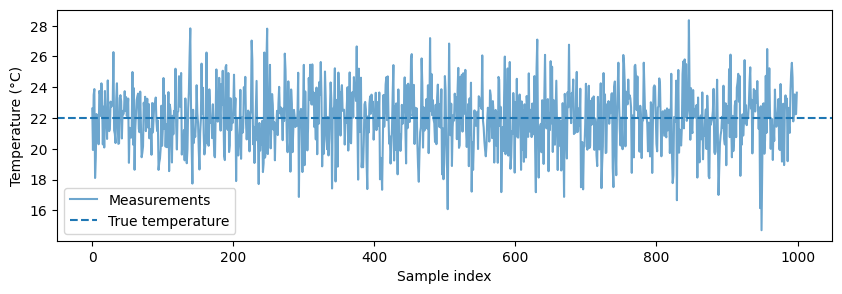

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)  # Reproducible random numbers
A = 22.0
sigma = 2.0
N = 1000
# One experiment: N independent measurements
x = A + rng.normal(0, sigma, size=N)
print("First five measurements:", x[:5])
plt.figure(figsize=(10, 3))
plt.plot(x, alpha=0.65, label="Measurements")
plt.axhline(A, linestyle="--", label="True temperature")
plt.xlabel("Sample index")
plt.ylabel("Temperature (°C)")
plt.legend(); plt.show()

## 2. Fisher information and CRLB
Independence gives the joint PDF as a product of Gaussian densities. Taking the natural logarithm gives

$$\ell(A)=-\frac{N}{2}\log(2\pi\sigma^2)-\frac{1}{2\sigma^2}\sum_{n=0}^{N-1}(x[n]-A)^2.$$

The first term is constant with respect to $A$. The first and second derivatives are

$$\ell'(A)=\frac{1}{\sigma^2}\sum_n(x[n]-A),\qquad \ell''(A)=-\frac{N}{\sigma^2}.$$

Therefore $\mathcal I(A)=-\mathbb E[\ell''(A)]=N/\sigma^2$ and every unbiased estimator satisfies $\operatorname{Var}(\hat A)\geq \sigma^2/N$.

We evaluate the log-PDF directly instead of multiplying many tiny probabilities, which can cause numerical underflow.

In [15]:
def log_likelihood(a, observations, sigma):
    return (-observations.size / 2 * np.log(2 * np.pi * sigma**2)
            - np.sum((observations - a)**2) / (2 * sigma**2))

def fisher_information(n, sigma):
    return n / sigma**2

def crlb(n, sigma):
    return 1 / fisher_information(n, sigma)

print("Fisher information:", fisher_information(N, sigma))
print("CRLB (°C²):", crlb(N, sigma))
print("Minimum standard deviation (°C):", np.sqrt(crlb(N, sigma)))
# Numerical check of the second derivative using finite differences
h = 0.01
curvature = (log_likelihood(A+h, x, sigma) - 2*log_likelihood(A, x, sigma)
             + log_likelihood(A-h, x, sigma)) / h**2
print("Numerical curvature:", curvature)
print("Theoretical curvature:", -fisher_information(N, sigma))

Fisher information: 250.0
CRLB (°C²): 0.004
Minimum standard deviation (°C): 0.06324555320336758
Numerical curvature: -249.99999999636202
Theoretical curvature: -250.0


## 3. Two estimators
Estimator 1 is the sample mean: $\hat A_1=\frac1N\sum_n x[n]$.

Estimator 2 generalizes the weighted estimator from the classroom exercise: $\hat A_2=\sum_n q_n x[n]$, where $q_n=(n+1)/\sum_{k=1}^N k$.

Both are unbiased because their weights sum to one. Independence gives $\operatorname{Var}(\hat A_2)=\sigma^2\sum_n q_n^2$. The mean has variance $\sigma^2/N$ and is efficient. The unequal weighted estimator has greater variance for $N>1$.

In [16]:
def weights(n):
    q = np.arange(1, n+1, dtype=float)
    return q / q.sum()

q = weights(N)
print("Sum of weights:", q.sum())
print("Sample mean:", x.mean())
print("Weighted estimate:", x @ q)
print("Theoretical weighted variance:", sigma**2 * np.sum(q**2))
# Reproduce the classroom numerical example
print("Classroom weighted estimate:", np.array([20,22,24,26]) @ weights(4))

Sum of weights: 1.0
Sample mean: 21.942216898008105
Weighted estimate: 21.942214099307144
Theoretical weighted variance: 0.00533066933066933
Classroom weighted estimate: 24.0


## 4. Monte Carlo experiments
A single experiment produces one estimate, not an estimator variance. Repeat the experiment $R$ times, each with $N$ fresh observations. Each row of the simulated matrix represents one experiment; each column represents one observation.

Empirical bias is the average estimate minus the true value. Empirical variance is the sample variance across the $R$ estimates (`ddof=1`). Theoretical efficiency is CRLB divided by theoretical variance for an unbiased estimator. Empirical ratios are approximate and can exceed 1 due to simulation uncertainty.

Mean: bias=0.00100, empirical variance=0.004056, theoretical variance=0.004000, theoretical efficiency=100.00%
Weighted: bias=0.00133, empirical variance=0.005430, theoretical variance=0.005331, theoretical efficiency=75.04%


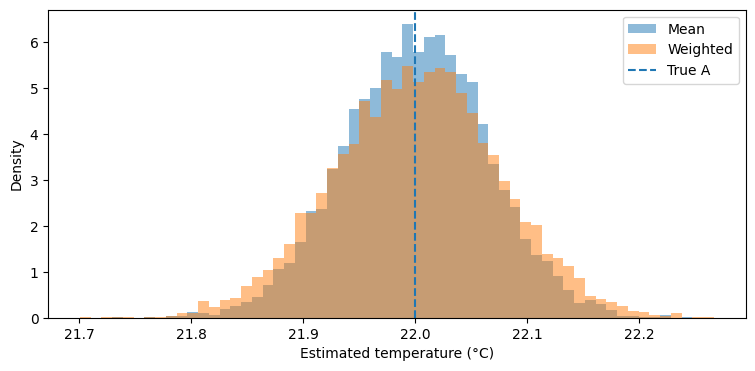

In [17]:
def simulate(n, repetitions, a, sigma, rng, batch_size=250):
    # Batch generation avoids allocating a huge R × N matrix.
    mean_est = np.empty(repetitions)
    weighted_est = np.empty(repetitions)
    q = weights(n)
    for start in range(0, repetitions, batch_size):
        stop = min(start + batch_size, repetitions)
        data = a + rng.normal(0, sigma, size=(stop-start, n))
        mean_est[start:stop] = data.mean(axis=1)
        weighted_est[start:stop] = data @ q
    return mean_est, weighted_est

R = 10000
mean_est, weighted_est = simulate(N, R, A, sigma, rng)
for name, estimates, theory in [
    ("Mean", mean_est, crlb(N, sigma)),
    ("Weighted", weighted_est, sigma**2 * np.sum(q**2))]:
    empirical = estimates.var(ddof=1)
    print(f"{name}: bias={estimates.mean()-A:.5f}, empirical variance={empirical:.6f}, "
          f"theoretical variance={theory:.6f}, theoretical efficiency={crlb(N,sigma)/theory:.2%}")

plt.figure(figsize=(9,4))
bins = np.linspace(min(mean_est.min(), weighted_est.min()),
                   max(mean_est.max(), weighted_est.max()), 60)
plt.hist(mean_est, bins=bins, density=True, alpha=.5, label="Mean")
plt.hist(weighted_est, bins=bins, density=True, alpha=.5, label="Weighted")
plt.axvline(A, linestyle="--", label="True A")
plt.xlabel("Estimated temperature (°C)"); plt.ylabel("Density")
plt.legend(); plt.show()

# Independent work
Complete the following cells and write short interpretations in Markdown. Use independent Gaussian noise unless otherwise specified. Report theoretical and empirical values separately. Keep random seeds reproducible.

### Task 1 — Noise and precision
For N=500 and R=5000, compare noise standard deviations 1, 2 and 5 °C. Calculate Fisher information, CRLB, empirical mean-estimator variance and bias. Plot empirical variance and CRLB against noise variance. Explain the trend.

In [10]:
# TODO: loop over noise standard deviations and collect results
noise_levels = [1, 2, 5]
# Your code here


### Task 2 — A different unbiased estimator
For even N, consider $\hat A_3=\frac{2}{N}\sum_{n=0}^{N/2-1}x[n]$ (only the first half of the observations).
Derive its expectation and variance using independence. Implement it for N=1000 and R=5000; compare empirical variance, theoretical variance, CRLB and efficiency. Explain why discarding observations affects precision.

In [11]:
# TODO: implement the estimator and run Monte Carlo experiments
N_task = 1000
R_task = 5000
# Your code here


### Task 3 — Biased estimator
Consider $\hat A_4=0.8\bar x$. Derive its bias, variance and mean squared error (MSE). Recall $\mathrm{MSE}=\operatorname{Var}(\hat A)+\mathrm{Bias}(\hat A)^2$.
For A=22, sigma=2 and N=1000, estimate these quantities using Monte Carlo and compare them with the theoretical values. Can its variance be below the unbiased CRLB? Explain why this does not contradict the theorem. Compare its MSE with that of the sample mean.

In [12]:
# TODO: generate repeated experiments and calculate bias, variance and MSE
# Your code here


### Task 4 — Design a measurement system
A sensor has noise standard deviation 3 °C. Find the minimum integer N for the sample mean to have standard deviation at most 0.1 °C. Verify by simulation at N and at a much smaller N (e.g. N/4). Explain why a finite simulation cannot reliably distinguish the precision at N from that at N−1. Use batching to control memory.

In [13]:
# TODO: calculate N and verify with simulate()
# Your code here


### Task 5 — Monte Carlo reliability
Fix N=100 and sigma=2. Repeat the variance assessment for R=50, 500 and 5000, using five independent seeds for each R. Plot or tabulate the five empirical variance estimates for each R alongside the CRLB. Explain why the results fluctuate and why increasing R does not change the theoretical CRLB.

**Deliverable:** completed notebook with code, plots, derivations and short interpretations for all five tasks.

In [14]:
# TODO: nested loops over repetitions and seeds
# Your code here
